# Systematic Hough Parameter Tuning Analysis
Interactive analysis and 2D response landscapes of the Hough Transform parameter space for dimuon track reconstruction in SND@LHC.

### Dataset Evaluated (24,192 total configurations):
- **GENIE Direct Charm Signal**: =215$ events (true primary + charm muon entering Downstream MuFilter)
- **Particle Gun Dimuon Signal**: =994$ events
- **GENIE Inclusive Background**: =500$ events
- **2022 Passing Muon Background**: =500$ events

### Objective Figure of Merit:
574553\text{Score} = (1 - \text{FPR}) \cdot (\text{TPR})^2574553
evaluated for each of the  \times 2 = 4$ signal vs background sample pairs.


In [1]:
# Fix ROOT JupyROOT RCanvas bug (disables broken automatic post_execute canvas capture)
try:
    ip = get_ipython()
    if ip and hasattr(ip, "events"):
        ip.events.callbacks["post_execute"] = [
            cb for cb in ip.events.callbacks.get("post_execute", [])
            if "CaptureDrawnPrimitives" not in str(cb) and "_post_execute" not in str(cb)
        ]
except Exception:
    pass

try:
    import ROOT
    ROOT.gROOT.SetBatch(True)
    if hasattr(ROOT, "_jupyroot"):
        import ROOT._jupyroot.helpers.utils as jutils
        jutils.GetRCanvasDrawers = lambda: []
        jutils.RCanvasAvailable = lambda: False
        jutils.CaptureDrawnPrimitives._post_execute = lambda self: None
except Exception:
    pass

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import ddfUtils.mpl_styling as dms
    has_dms = True
except ImportError:
    has_dms = False

plt.style.use("root" if "root" in plt.style.available else "default")
plt.rcParams.update({"font.size": 12, "figure.autolayout": True})


## 1. Load Tuning Grid Results from CSV

In [2]:
csv_path = "../pgun/plots/hough_fom_pairwise_results.csv"
if not os.path.exists(csv_path):
    csv_path = "/eos/user/i/idioniso/snd-numu-charm/plots/hough_tuning/hough_fom_pairwise_results.csv"

df = pd.read_csv(csv_path)
print(f"Loaded {len(df):,} configurations from {csv_path}")
df.head(5)


Loaded 24,192 configurations from /eos/user/i/idioniso/snd-numu-charm/plots/hough_tuning/hough_fom_pairwise_results.csv


,format,max_angle,max_opening_angle,binning_factor,n_xH,n_yH,tolerance,smooth_full,sigma,truncate,TPR_genie,TPR_pgun,FPR_genie,FPR_pmu,score_genie_genie,score_genie_pmu,score_pgun_genie,score_pgun_pmu,score_mean
0,linearSlopeIntercept,0.2,0.20,2.9,638,354,0.5,True,0.5,1.0,0.995349,0.802817,0.068,0.126,0.92335,0.865889,0.600688,0.563306,0.738308
1,linearSlopeIntercept,0.2,0.20,2.9,638,354,0.5,True,0.5,2.0,0.995349,0.802817,0.068,0.126,0.92335,0.865889,0.600688,0.563306,0.738308
2,linearSlopeIntercept,0.2,0.20,2.9,638,354,0.5,True,0.5,3.0,0.995349,0.792757,0.068,0.112,0.92335,0.879759,0.585727,0.558075,0.736728
3,linearSlopeIntercept,0.2,0.20,2.9,638,354,0.5,True,0.5,4.0,0.995349,0.792757,0.068,0.112,0.92335,0.879759,0.585727,0.558075,0.736728
4,linearSlopeIntercept,0.2,0.25,2.9,638,354,0.5,True,0.5,1.0,0.995349,0.802817,0.068,0.126,0.92335,0.865889,0.600688,0.563306,0.738308


## 2. Identify the Best Parameter Set (Rank 1)

In [3]:
best_row = df.sort_values(by="score_genie_genie", ascending=False).iloc[0]
best_params = {
    "format": best_row["format"],
    "max_angle": float(best_row["max_angle"]),
    "max_opening_angle": float(best_row["max_opening_angle"]),
    "binning_factor": float(best_row["binning_factor"]),
    "n_xH": int(best_row["n_xH"]),
    "n_yH": int(best_row["n_yH"]),
    "tolerance": float(best_row["tolerance"]),
    "smooth_full": bool(best_row["smooth_full"]),
    "sigma": float(best_row["sigma"]),
    "truncate": float(best_row["truncate"]),
}

print("=" * 65)
print(" OPTIMAL PARAMETER SET (RANK 1)")
print("=" * 65)
for k, v in best_params.items():
    print(f"  {k:<22}: {v}")
print("-" * 65)
print(f"  TPR (GENIE Signal)    : {best_row['TPR_genie']*100:.2f}%")
print(f"  FPR (GENIE Bkg)       : {best_row['FPR_genie']*100:.2f}% (Rejection: {(1-best_row['FPR_genie'])*100:.2f}%)")
print(f"  Score (GENIE vs GENIE): {best_row['score_genie_genie']:.4f}")
print(f"  Score (GENIE vs PMU)  : {best_row['score_genie_pmu']:.4f}")
print(f"  Score (PGUN vs GENIE) : {best_row['score_pgun_genie']:.4f}")
print(f"  Score (PGUN vs PMU)   : {best_row['score_pgun_pmu']:.4f}")
print(f"  Composite Mean Score  : {best_row['score_mean']:.4f}")
print("=" * 65)


 OPTIMAL PARAMETER SET (RANK 1)
  format                : linearSlopeIntercept
  max_angle             : 0.2
  max_opening_angle     : 0.2
  binning_factor        : 2.9
  n_xH                  : 638
  n_yH                  : 354
  tolerance             : 0.5
  smooth_full           : True
  sigma                 : 0.5
  truncate              : 1.0
-----------------------------------------------------------------
  TPR (GENIE Signal)    : 99.53%
  FPR (GENIE Bkg)       : 6.80% (Rejection: 93.20%)
  Score (GENIE vs GENIE): 0.9234
  Score (GENIE vs PMU)  : 0.8659
  Score (PGUN vs GENIE) : 0.6007
  Score (PGUN vs PMU)   : 0.5633
  Composite Mean Score  : 0.7383


## 3. 2D Response Landscapes: Hit Tolerance vs Binning Factor
Slicing the grid at the optimal max angle, max opening angle, and Gaussian smoothing parameters.
We mark the **Rank 1 best set** with a red star on each heatmap.


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


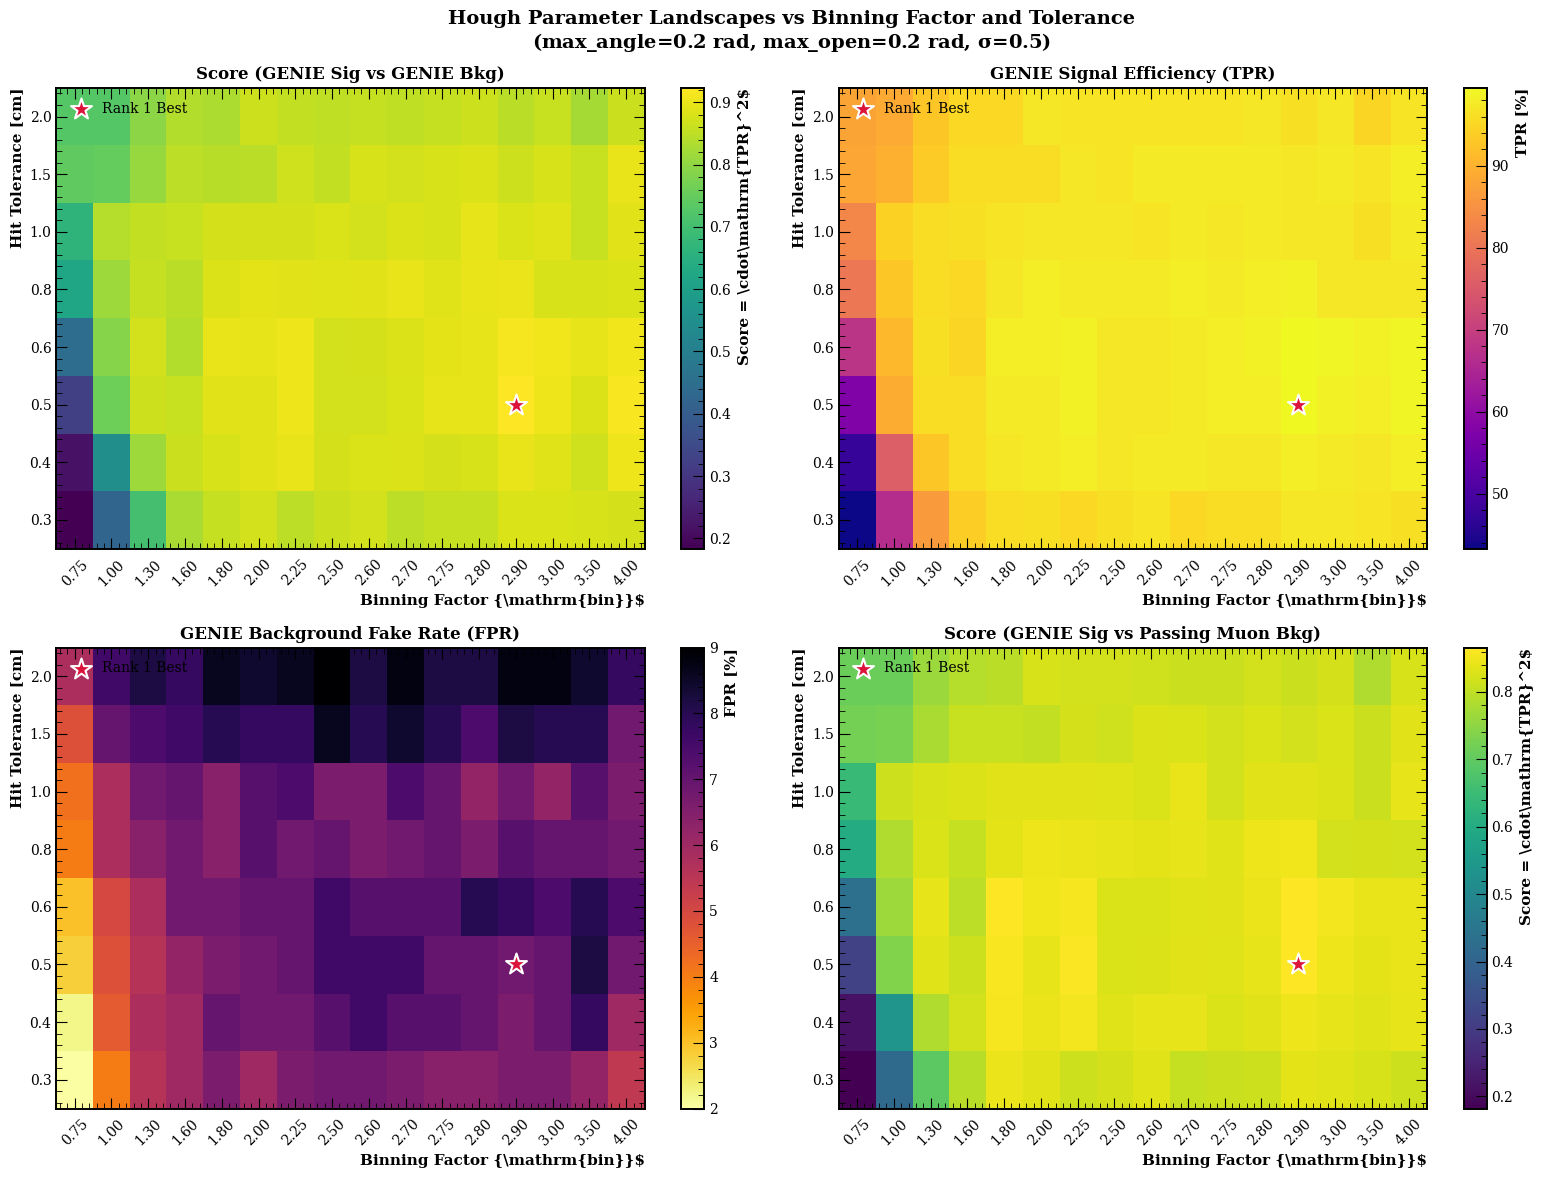

In [4]:
# Filter slice around optimal max_angle, max_opening_angle, and smoothing parameters
slice_df = df[
    (df["format"] == best_params["format"]) &
    (df["max_angle"] == best_params["max_angle"]) &
    (df["max_opening_angle"] == best_params["max_opening_angle"]) &
    (df["smooth_full"] == best_params["smooth_full"]) &
    (df["sigma"] == best_params["sigma"]) &
    (df["truncate"] == best_params["truncate"])
].copy()

piv_score_gg = slice_df.pivot(index="tolerance", columns="binning_factor", values="score_genie_genie")
piv_tpr_g = slice_df.pivot(index="tolerance", columns="binning_factor", values="TPR_genie") * 100.0
piv_fpr_g = slice_df.pivot(index="tolerance", columns="binning_factor", values="FPR_genie") * 100.0
piv_score_gp = slice_df.pivot(index="tolerance", columns="binning_factor", values="score_genie_pmu")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

panels = [
    (axes[0, 0], piv_score_gg, r"Score (GENIE Sig vs GENIE Bkg)", "Score = \cdot\mathrm{TPR}^2$", "viridis"),
    (axes[0, 1], piv_tpr_g, r"GENIE Signal Efficiency (TPR)", "TPR [%]", "plasma"),
    (axes[1, 0], piv_fpr_g, r"GENIE Background Fake Rate (FPR)", "FPR [%]", "inferno_r"),
    (axes[1, 1], piv_score_gp, r"Score (GENIE Sig vs Passing Muon Bkg)", "Score = \cdot\mathrm{TPR}^2$", "viridis"),
]

for ax, piv, title, cbar_lbl, cmap in panels:
    im = ax.imshow(piv.values, origin="lower", cmap=cmap, aspect="auto")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_lbl, fontsize=11)
    
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([f"{v:.2f}" for v in piv.columns], rotation=45, fontsize=10)
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels([f"{v:.1f}" for v in piv.index], fontsize=10)
    ax.set_xlabel("Binning Factor {\mathrm{bin}}$", fontsize=11)
    ax.set_ylabel("Hit Tolerance [cm]", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight="bold")
    
    # Mark the optimal configuration
    opt_x = list(piv.columns).index(best_params["binning_factor"])
    opt_y = list(piv.index).index(best_params["tolerance"])
    ax.scatter([opt_x], [opt_y], s=250, color="crimson", marker="*", edgecolor="white", linewidth=1.5, zorder=5, label="Rank 1 Best")
    ax.legend(loc="upper left", fontsize=10)

plt.suptitle(f"Hough Parameter Landscapes vs Binning Factor and Tolerance\n(max_angle={best_params['max_angle']} rad, max_open={best_params['max_opening_angle']} rad, $\sigma$={best_params['sigma']})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. The 2x2 Score Matrix: Generalization Across Datasets
How well does the best parameter set transfer across different signal simulations and background environments?
1. **GENIE vs GENIE**: Standard neutrino DIS benchmark
2. **GENIE vs PMU**: Physics signal against single passing muon punch-through
3. **PGun vs GENIE**: Clean dimuon kinematics against hadronic shower noise
4. **PGun vs PMU**: Clean dimuon kinematics against single muon background


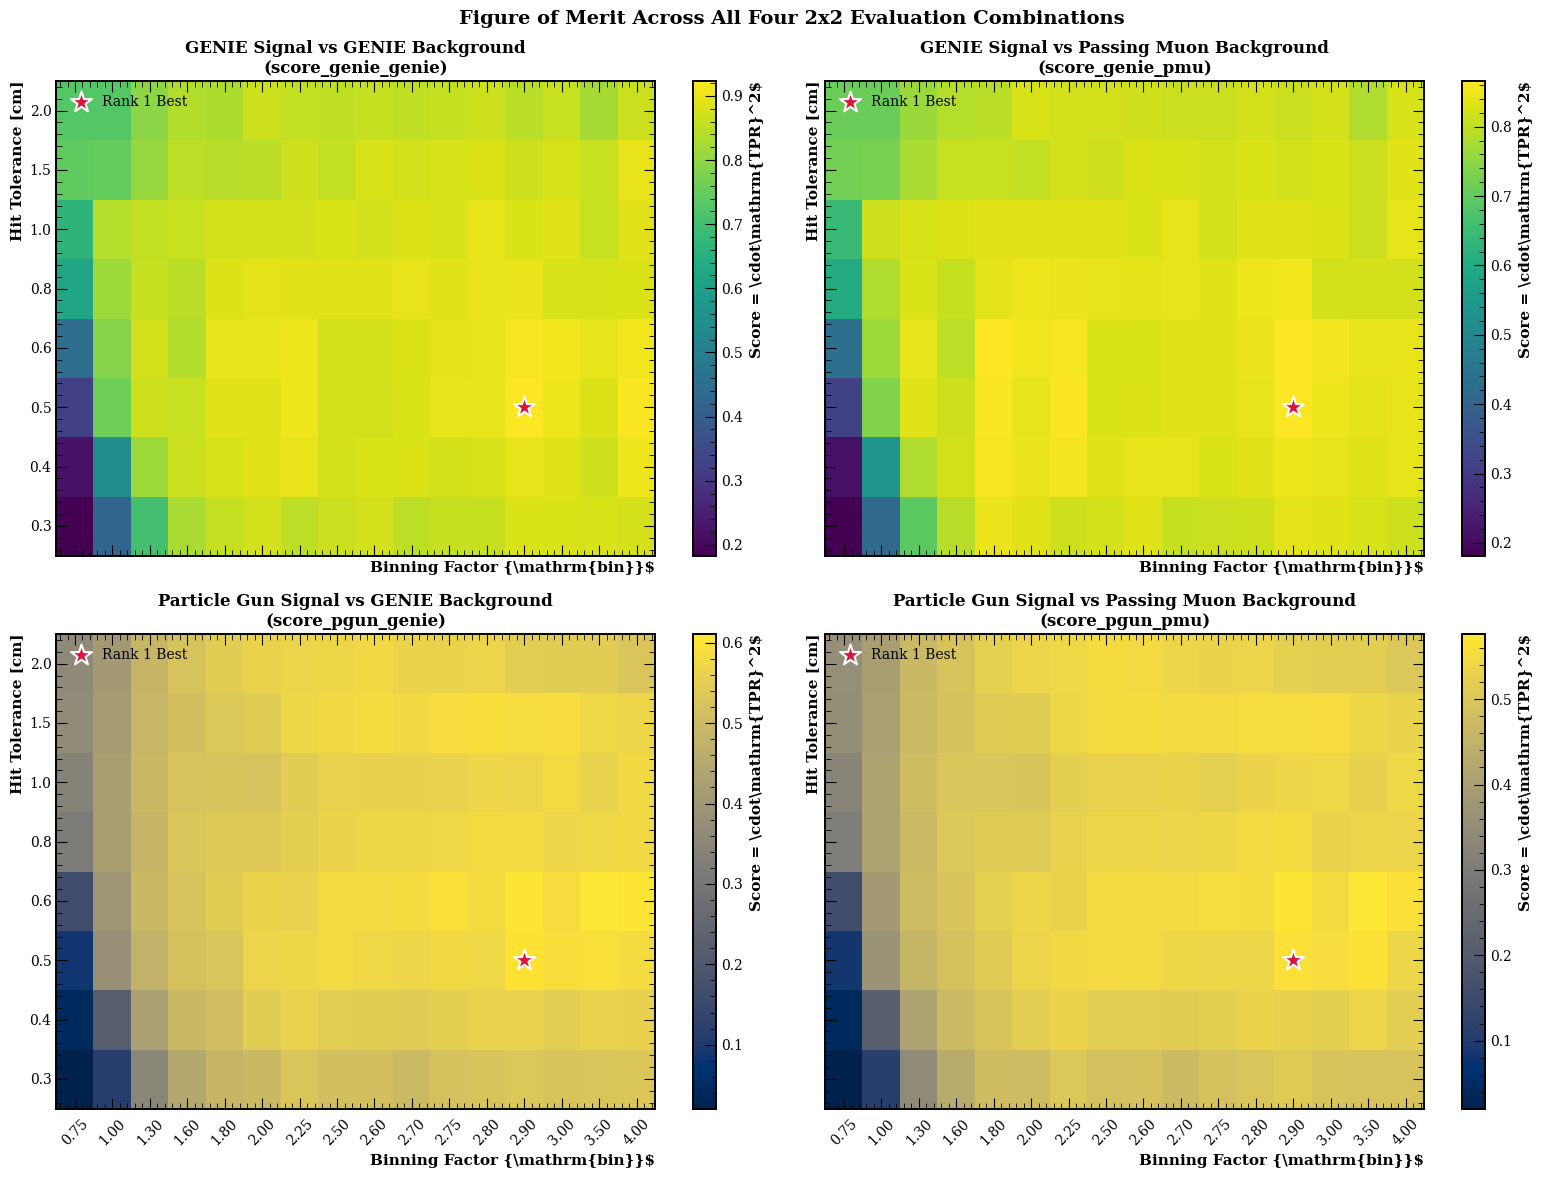

In [5]:
piv_gg = slice_df.pivot(index="tolerance", columns="binning_factor", values="score_genie_genie")
piv_gp = slice_df.pivot(index="tolerance", columns="binning_factor", values="score_genie_pmu")
piv_pg = slice_df.pivot(index="tolerance", columns="binning_factor", values="score_pgun_genie")
piv_pp = slice_df.pivot(index="tolerance", columns="binning_factor", values="score_pgun_pmu")

fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True)

matrix_panels = [
    (axes[0, 0], piv_gg, "GENIE Signal vs GENIE Background\n(score_genie_genie)", "viridis"),
    (axes[0, 1], piv_gp, "GENIE Signal vs Passing Muon Background\n(score_genie_pmu)", "viridis"),
    (axes[1, 0], piv_pg, "Particle Gun Signal vs GENIE Background\n(score_pgun_genie)", "cividis"),
    (axes[1, 1], piv_pp, "Particle Gun Signal vs Passing Muon Background\n(score_pgun_pmu)", "cividis"),
]

for ax, piv, title, cmap in matrix_panels:
    im = ax.imshow(piv.values, origin="lower", cmap=cmap, aspect="auto")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Score = \cdot\mathrm{TPR}^2$", fontsize=11)
    
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([f"{v:.2f}" for v in piv.columns], rotation=45, fontsize=10)
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels([f"{v:.1f}" for v in piv.index], fontsize=10)
    ax.set_xlabel("Binning Factor {\mathrm{bin}}$", fontsize=11)
    ax.set_ylabel("Hit Tolerance [cm]", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight="bold")
    
    # Mark the optimal configuration
    opt_x = list(piv.columns).index(best_params["binning_factor"])
    opt_y = list(piv.index).index(best_params["tolerance"])
    ax.scatter([opt_x], [opt_y], s=250, color="crimson", marker="*", edgecolor="white", linewidth=1.5, zorder=5, label="Rank 1 Best")
    ax.legend(loc="upper left", fontsize=10)

plt.suptitle("Figure of Merit Across All Four 2x2 Evaluation Combinations", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Smoothing Hyperparameters: Impact of Gaussian $\sigma$ and Truncation Factor
At optimal binning factor (.90$) and tolerance (bash.5$ cm), how does Gaussian accumulator smoothing affect the score?


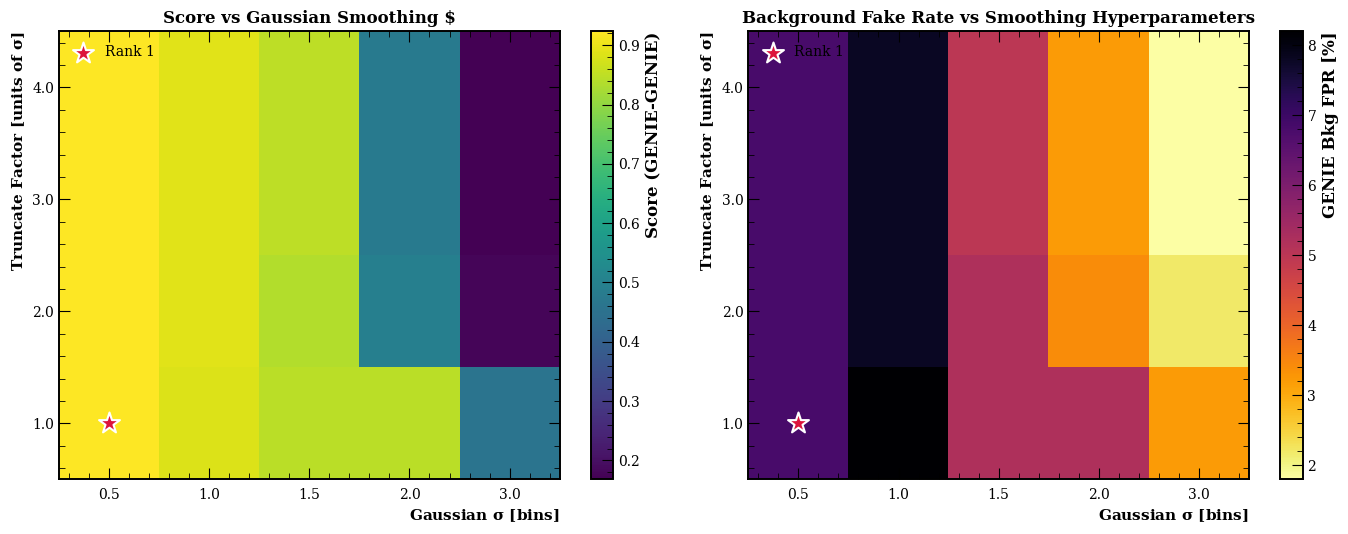

In [6]:
smooth_df = df[
    (df["format"] == best_params["format"]) &
    (df["max_angle"] == best_params["max_angle"]) &
    (df["max_opening_angle"] == best_params["max_opening_angle"]) &
    (df["binning_factor"] == best_params["binning_factor"]) &
    (df["tolerance"] == best_params["tolerance"]) &
    (df["smooth_full"] == True)
].copy()

piv_smooth_score = smooth_df.pivot(index="truncate", columns="sigma", values="score_genie_genie")
piv_smooth_fpr = smooth_df.pivot(index="truncate", columns="sigma", values="FPR_genie") * 100.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

im0 = axes[0].imshow(piv_smooth_score.values, origin="lower", cmap="viridis", aspect="auto")
fig.colorbar(im0, ax=axes[0], label="Score (GENIE-GENIE)")
axes[0].set_xticks(range(len(piv_smooth_score.columns)))
axes[0].set_xticklabels([f"{v:.1f}" for v in piv_smooth_score.columns])
axes[0].set_yticks(range(len(piv_smooth_score.index)))
axes[0].set_yticklabels([f"{v:.1f}" for v in piv_smooth_score.index])
axes[0].set_xlabel("Gaussian $\sigma$ [bins]", fontsize=11)
axes[0].set_ylabel("Truncate Factor [units of $\sigma$]", fontsize=11)
axes[0].set_title("Score vs Gaussian Smoothing $", fontsize=12, fontweight="bold")

best_sig_x = list(piv_smooth_score.columns).index(best_params["sigma"])
best_trn_y = list(piv_smooth_score.index).index(best_params["truncate"])
axes[0].scatter([best_sig_x], [best_trn_y], s=250, color="crimson", marker="*", edgecolor="white", linewidth=1.5, zorder=5, label="Rank 1")
axes[0].legend(loc="upper left")

im1 = axes[1].imshow(piv_smooth_fpr.values, origin="lower", cmap="inferno_r", aspect="auto")
fig.colorbar(im1, ax=axes[1], label="GENIE Bkg FPR [%]")
axes[1].set_xticks(range(len(piv_smooth_fpr.columns)))
axes[1].set_xticklabels([f"{v:.1f}" for v in piv_smooth_fpr.columns])
axes[1].set_yticks(range(len(piv_smooth_fpr.index)))
axes[1].set_yticklabels([f"{v:.1f}" for v in piv_smooth_fpr.index])
axes[1].set_xlabel("Gaussian $\sigma$ [bins]", fontsize=11)
axes[1].set_ylabel("Truncate Factor [units of $\sigma$]", fontsize=11)
axes[1].set_title("Background Fake Rate vs Smoothing Hyperparameters", fontsize=12, fontweight="bold")
axes[1].scatter([best_sig_x], [best_trn_y], s=250, color="crimson", marker="*", edgecolor="white", linewidth=1.5, zorder=5, label="Rank 1")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()


## 6. Global Score Distribution: Best Set vs Full Parameter Space

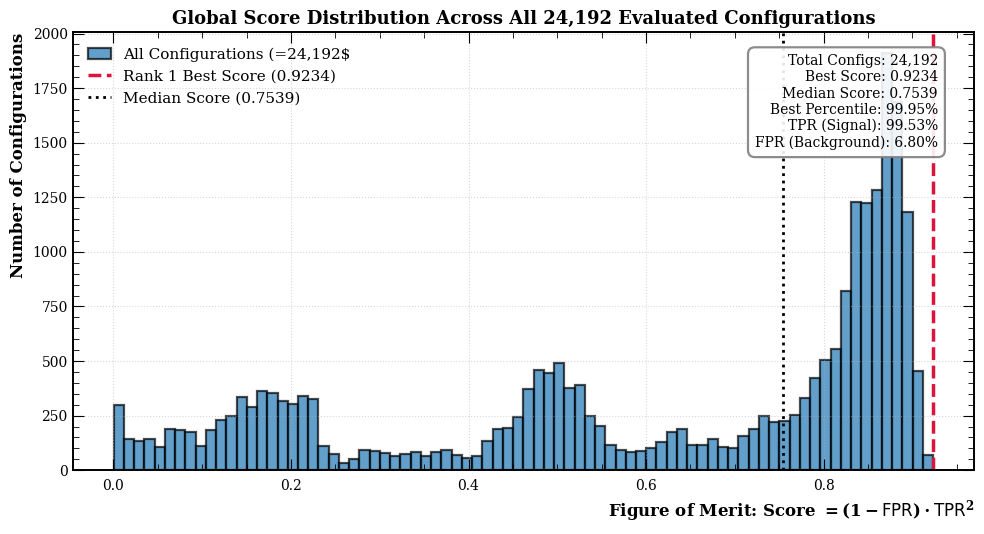

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))

scores_all = df["score_genie_genie"].values
ax.hist(scores_all, bins=80, color="#1f77b4", alpha=0.7, edgecolor="black", label=f"All Configurations (={len(scores_all):,}$")
ax.axvline(best_row["score_genie_genie"], color="crimson", linestyle="--", linewidth=2.5,
           label=f"Rank 1 Best Score ({best_row['score_genie_genie']:.4f})")
ax.axvline(np.median(scores_all), color="black", linestyle=":", linewidth=2.0,
           label=f"Median Score ({np.median(scores_all):.4f})")

percentile = (scores_all < best_row["score_genie_genie"]).mean() * 100.0

ax.set_xlabel("Figure of Merit: Score $= (1 - \mathrm{FPR})\cdot\mathrm{TPR}^2$", fontsize=12)
ax.set_ylabel("Number of Configurations", fontsize=12)
ax.set_title("Global Score Distribution Across All 24,192 Evaluated Configurations", fontsize=13, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper left", fontsize=11)

stats_box = (
    f"Total Configs: {len(df):,}\n"
    f"Best Score: {best_row['score_genie_genie']:.4f}\n"
    f"Median Score: {np.median(scores_all):.4f}\n"
    f"Best Percentile: {percentile:.2f}%\n"
    f"TPR (Signal): {best_row['TPR_genie']*100:.2f}%\n"
    f"FPR (Background): {best_row['FPR_genie']*100:.2f}%"
)
ax.text(0.96, 0.95, stats_box, transform=ax.transAxes, fontsize=10,
        verticalalignment="top", horizontalalignment="right",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9, edgecolor="gray"))

plt.tight_layout()
plt.show()
